# Learning curves: `run-2_original-baseline-six-windows`
Run the cell below once; it refreshes itself until training ends.

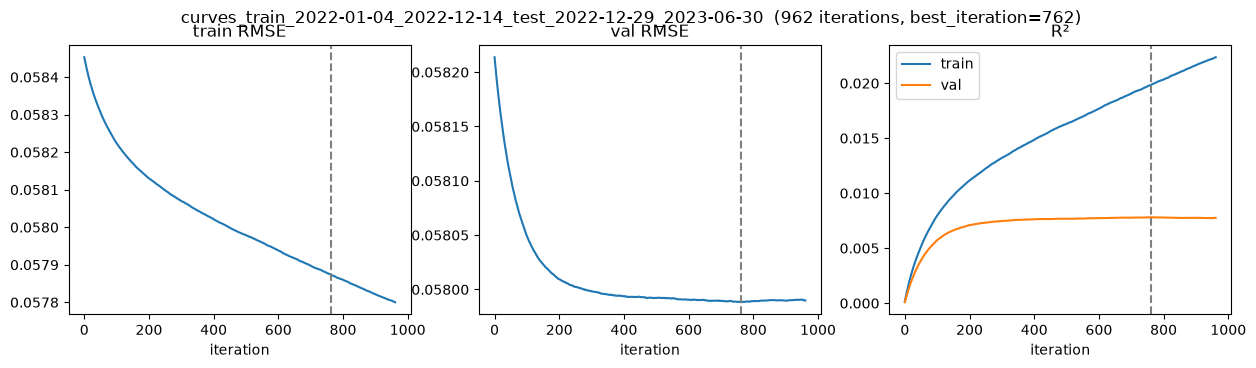

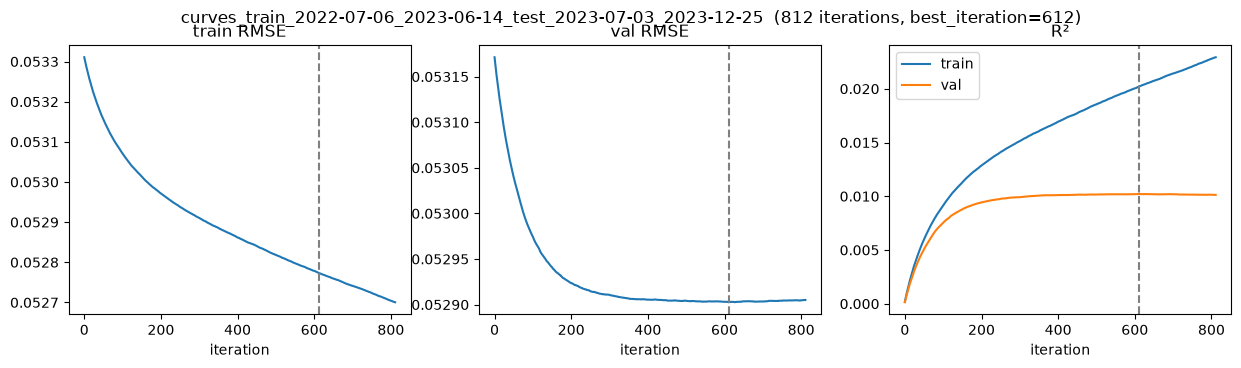

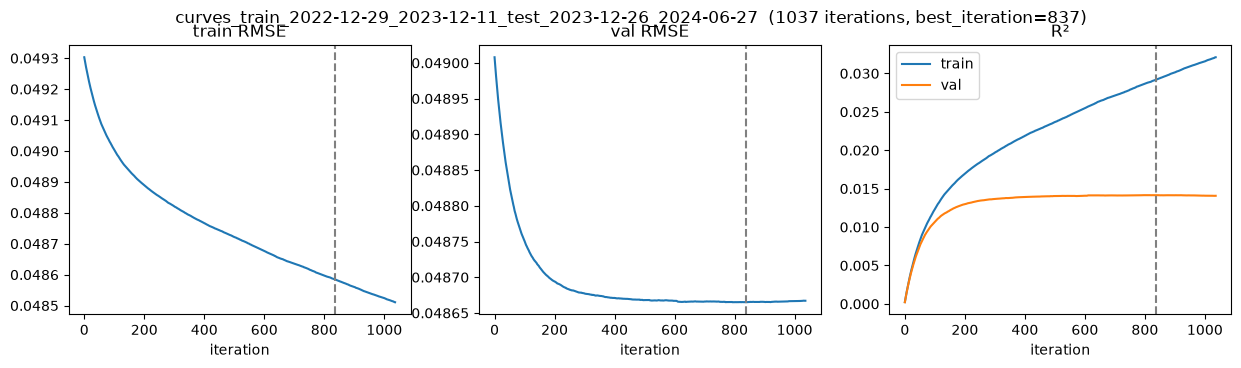

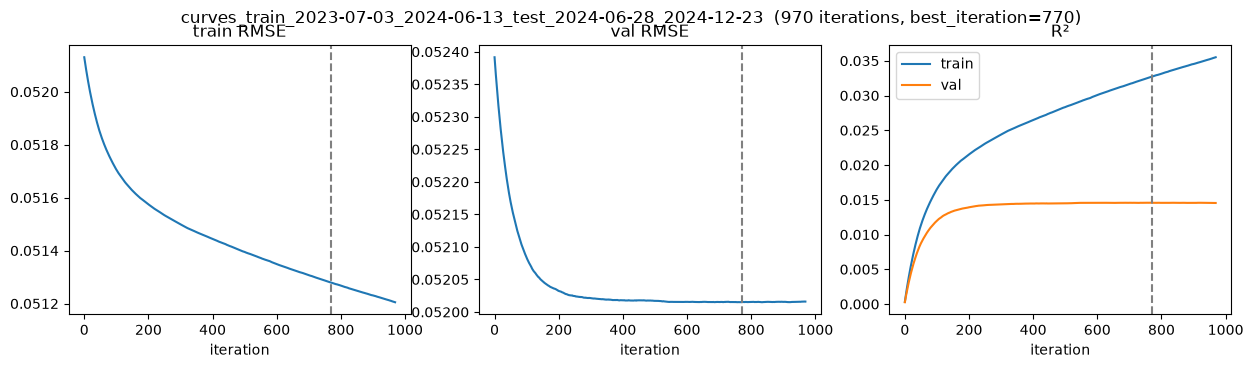

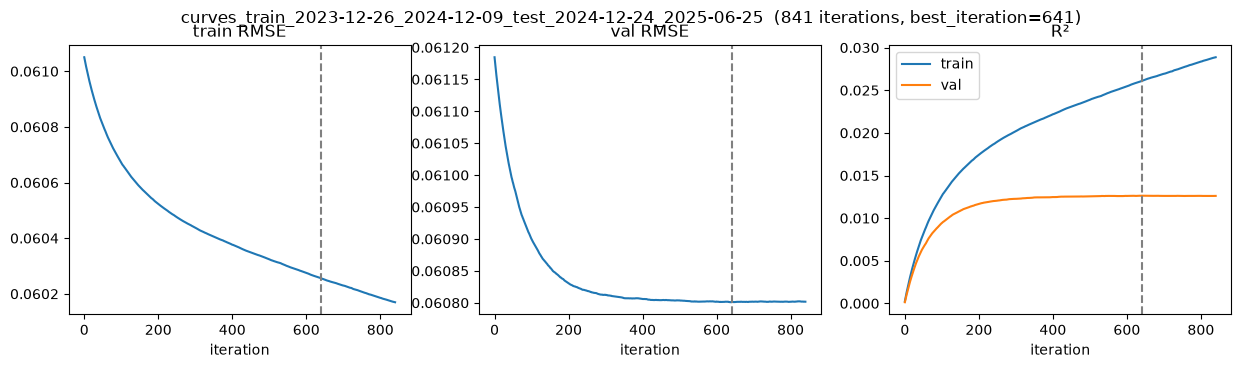

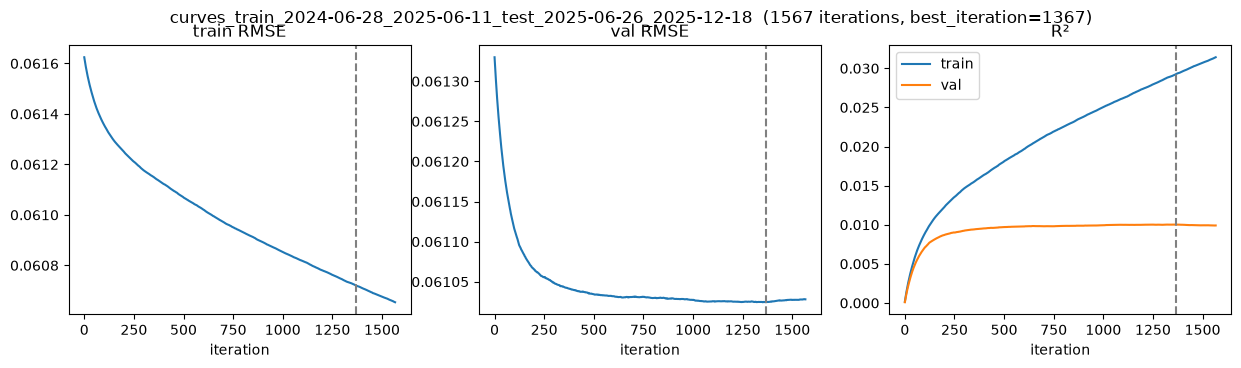

13:44:08: training process has exited. Final plot.


In [2]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import clear_output

RUN_DIR = Path("/workspaces/TimeSeries48/runs/run-2_original-baseline-six-windows")
TRAIN_PID = 399469      # Process ID of the training script.
REFRESH_SECONDS = 5


def training_alive() -> bool:
    """True while the training process still exists."""
    return Path(f"/proc/{TRAIN_PID}").exists()


def plot_curves() -> None:
    """Plot train/val RMSE and R² for every window's curves file."""
    files = sorted(RUN_DIR.glob("curves_*.json"))
    if not files:
        print("No curves yet: training just started...")
    for f in files:
        try:
            d = json.loads(f.read_text())
        except (OSError, json.JSONDecodeError):
            continue
        best, c = d["best_iteration"], d["curves"]
        fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
        axes[0].plot(c["train"]["rmse"])
        axes[0].set_title("train RMSE")
        axes[1].plot(c["val"]["rmse"])
        axes[1].set_title("val RMSE")
        axes[2].plot(c["train"]["r2"], label="train")
        axes[2].plot(c["val"]["r2"], label="val")
        axes[2].set_title("R²")
        axes[2].legend()
        for ax in axes:
            ax.set_xlabel("iteration")
            if best is not None:
                ax.axvline(best, ls="--", c="gray")  # Best iteration.
        status = f"best_iteration={best}" if best is not None else "training..."
        fig.suptitle(f"{f.stem}  ({len(c['val']['rmse'])} iterations, {status})")
        plt.show()


# Refresh until the training process exits, then draw a final plot and stop.
# Interrupt the cell (stop button) to end it early; training is unaffected.
while True:
    alive = training_alive()
    clear_output(wait=True)
    plot_curves()
    stamp = time.strftime("%H:%M:%S")
    if not alive:
        print(f"{stamp}: training process has exited. Final plot.")
        break
    print(f"{stamp}: training running (PID {TRAIN_PID})...")
    time.sleep(REFRESH_SECONDS)
